https://arxiv.org/abs/2010.11929

In [4]:
import torch
import torch.nn as nn
# from diffusers import AutoencoderKL
import matplotlib.pyplot as plt

get data (thx claude)

In [6]:
from datasets import load_dataset
import torch
import torchvision.transforms as T


train_ds = load_dataset("uoft-cs/cifar10", split="train", streaming=True)
train_ds = train_ds.shuffle(buffer_size=10_000, seed=0).take(1000) # out of 50k examples

train_tf = T.Compose([
      T.RandomHorizontalFlip(),
      T.ToTensor(),                       # [0, 1]
      T.Normalize([0.5]*3, [0.5]*3),      # → [-1, 1]
])

def collate(batch):
    x = torch.stack([train_tf(b["img"]) for b in batch])   # same transforms as before
    y = torch.tensor([b["label"] for b in batch])
    return x, y

train_dl = torch.utils.data.DataLoader(train_ds, batch_size=128, collate_fn=collate)

val_ds = load_dataset("uoft-cs/cifar10", split="test", streaming=True).take(100)
val_dl = torch.utils.data.DataLoader(val_ds, batch_size=256, collate_fn=collate)  # val_collate uses test_tf

Okay just adapting ViT to DiT with minimal changes. There are various inefficiencies we'll address in a later notebook

In [7]:

class Block(nn.Module):
	def __init__(self, C, d, nheads):
		super().__init__()

		self.C, self.d = C, d

		self.heads = nn.MultiheadAttention(C, nheads, batch_first=True)
		self.mlp = nn.Sequential(
			nn.Linear(C, C*4),
			nn.GELU(), # better for VITs
			nn.Linear(C*4, C),
		)
		self.ln1 = nn.LayerNorm(C)
		self.ln2 = nn.LayerNorm(C)

	def forward(self, x):
		h = self.ln1(x)
		out, _ = self.heads(h, h, h, need_weights=False)
		x = x + self.mlp(self.ln2(out))
		return x


class DiT(nn.Module):
	def __init__(self, channels=3, H=32, W=32, patch_per_side=4,
		embedding_size=192, nheads=4, nblocks=6, total_t=1000, num_classes=10):
		super().__init__()

		self.P, self.C = patch_per_side, embedding_size

		self.channels, self.H, self.W = channels, H, W

		P = self.P
		EMB = self.C

		assert EMB % nheads == 0
		self.d = EMB // nheads


		self.emb = nn.Linear(self.channels * (H//P)  * (W//P), EMB)
		self.pos = nn.Embedding(P*P, EMB)
		nn.init.trunc_normal_(self.pos.weight, std=0.02)

		self.y_emb = nn.Embedding(num_classes+1, EMB)
		self.t_emb = nn.Embedding(total_t, EMB)
		nn.init.trunc_normal_(self.y_emb.weight, std=0.02)
		nn.init.trunc_normal_(self.t_emb.weight, std=0.02)

		self.blocks = nn.ModuleList([Block(EMB, self.d, nheads) for _ in range(nblocks)])

		self.final = nn.Linear(EMB, channels * (H//P) * (W//P))
	
	def forward(self, x_t, t, y):
		B, channels, H, W = x_t.shape
		assert channels == self.channels and H == self.H and W == self.W

		# LOOK at ViT
		P = self.P
		patches = x_t.reshape(B, channels, P, H // P, P, W // P)
		patches = patches.permute(0, 2, 4, 1, 3, 5)
		patches = patches.reshape(B, P * P, -1)
		x = self.emb(patches) + self.pos(torch.arange(P*P, device=x_t.device))

		c = self.y_emb(y) + self.t_emb(t)
		
		# just add the conditioning (can fade) to embeddings
		x = x + c[:, None, :]

		for block in self.blocks:
			x = block(x)

		# (B, P*P, EMB) -> (B, P*P, channels*H//P *W//P)
		noise = self.final(x)

		# unpermute
		noise = noise.reshape(B, P, P, channels, H // P, W // P)
		noise = noise.permute(0, 3, 1, 4, 2, 5)
		noise = noise.reshape(B, channels, H, W)
		return noise

mymodel = DiT()

In [10]:

T = 1000
# (1-beta_t) is that timestep's mixing of noise, decreases as t->0
# x_t+1 = sqrt(1 - beta_t) * x_t + sqrt(beta_t) * eps
beta = torch.linspace(1e-4, 0.02, T)
# abar = (1-beta_0)...(1-beta_t)
abar = torch.cumprod(1 - beta, dim=0)

optimizer = torch.optim.AdamW(mymodel.parameters(), lr=1e-4, weight_decay=0) 

lossi = []

for epoch in range(1):
	for x, y in train_dl:

		B, C, H, W = x.shape

		# random noise
		noise = torch.randn_like(x)
		
		# random sample of current timestep
		t = torch.randint(0, T, (B,))

		# cum a up to that timestep
		# find the "gain" of noise at that timestep
		a = abar[t].view(B, 1, 1, 1)

		# dial how strong noise should be at that timestep (for when we slowly remove noise)
		# sqrt(a) * x0 + sqrt(1-a) * noise
		x_t = torch.sqrt(a) * x + torch.sqrt(1-a) * noise

		# add "dropout" for label. for unconditional mode (aka don't need it to generate image)
		drop_mask = torch.rand(B) < 0.1
		y = torch.where(drop_mask, torch.full_like(y, 10), y)

		# INIT
		pred_noise = mymodel(x_t, t, y)
		loss = ((pred_noise - noise)**2).mean()

		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

		lossi.append(loss.item())

print(loss.item())

1.1105115413665771


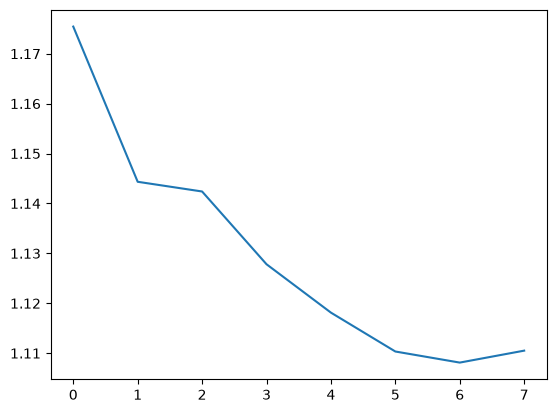

In [11]:
plt.plot(lossi)

In [15]:
import matplotlib.pyplot as plt

def show(img):
    img = (img.detach().cpu() + 1) / 2          # [-1, 1] → [0, 1]
    img = img.clamp(0, 1).permute(1, 2, 0)      # (C, H, W) → (H, W, C)
    plt.figure(figsize=(2, 2)) 
    plt.imshow(img)
    plt.axis("off")
    plt.show()

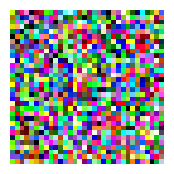

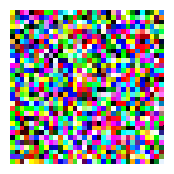

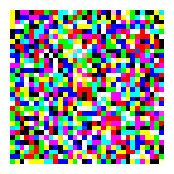

In [23]:
ts = torch.linspace(T - 1, 0, 50).long()

# random noise
x = torch.randn(1, mymodel.channels, mymodel.H, mymodel.W)
y = torch.tensor([0])

show(x[0])

for i, t in enumerate(ts):
    eps = mymodel(x, t, y)

    # DDIM
    a_t = abar[t]
    a_prev = abar[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0)

    # x_t-1 = sqrt(a) * x0   +   sqrt(1-a) * eps

    # blurry "prediction" of original image using our predicted noise
    # ==> x0 = ...         reverse
    x0 = ((x - (1 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-1, 1)

    # due to clamping, eps is now slightly different. sync pls
    # ===> esp = ...
    eps = (x - a_t.sqrt() * x0) / (1 - a_t).sqrt()

    # use the estimate of x0 and eps to predict the next iteration of image
    # x_t-1 = ...
    x = a_prev.sqrt() * x0 + (1 - a_prev).sqrt() * eps

    if i == len(ts) // 2:
        show(x[0])

show(x[0])